### 03. SHAP Explainability

This notebook analyzes the Gradient Boosting correction model using SHAP
(SHapley Additive exPlanations) to identify which geometric descriptors
drive the predicted correction, and how. It first reproduces the baseline
feature importance analysis, then extends it with SHAP interaction values
and dependence plots to characterize how the three predictors
(volume ratio, length ratio, Dice similarity std) jointly influence the
model's output.

Subgroup-level SHAP comparisons across clinical categories (HFrEF, HFmrEF,
Normal EF) are addressed separately in notebook 04.

All analyses in this notebook are performed on the TEST split, consistent
with notebook 02.

- **Inputs:** `models/gb_correction.joblib`, `data/processed/inference_with_corrections.csv`
- **Outputs:** SHAP summary, interaction, and dependence plots saved to `figures/`.

#### Load model and data

In [6]:
import sys
sys.path.append('..')

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns

reg = joblib.load("../models/gb_correction.joblib")
data = pd.read_csv("../data/processed/inference_with_corrections.csv")

test = data[data['split'] == 'TEST'].copy()
features = ['volume_ratio', 'length_ratio', 'dice_overlap_std']
X_test = test[features]

#### Baseline SHAP values

Compute SHAP values for the correction model on TEST, using
`TreeExplainer` (exact for tree-based models like Gradient Boosting). This
reproduces the original feature-relevance analysis as a starting point.

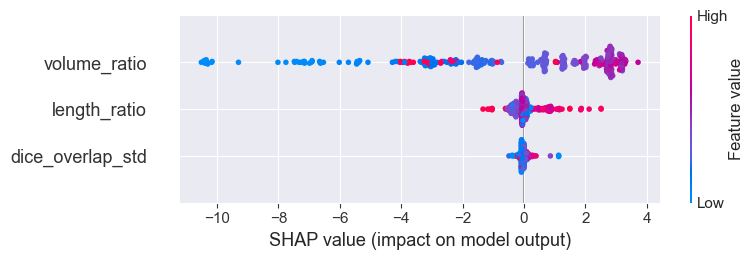

In [7]:
explainer = shap.TreeExplainer(reg)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig('../figures/shap_summary.png', dpi=200, bbox_inches='tight')
plt.show()

Volume ratio is the dominant predictor, with a clear separation between
low values and high values consistent with the original
analysis. Length ratio and Dice similarity std contribute smaller,
tighter-ranged effects, suggesting the model's correction is primarily
driven by volumetric dynamics rather than segmentation temporal stability.

#### SHAP interaction values

Interaction values decompose each SHAP value into a main effect and
pairwise interaction effects, showing whether the impact of one feature on
the correction depends on the value of another. This is particularly
relevant given the strong correlation observed between volume ratio and
length ratio in the original analysis (Pearson r = 0.892), despite
combining them not improving model performance.

In [8]:
shap_interaction_values = explainer.shap_interaction_values(X_test)

# Mean absolute interaction strength between each pair of features
interaction_matrix = np.abs(shap_interaction_values).mean(axis=0)

interaction_df = pd.DataFrame(interaction_matrix, index=features, columns=features)
interaction_df

,volume_ratio,length_ratio,dice_overlap_std
volume_ratio,2.658599,0.175881,0.059600
length_ratio,0.175881,0.261946,0.018225
dice_overlap_std,0.059600,0.018225,0.083996


Main effects dominate over interactions: volume ratio's main effect
(2.659) is ~15x larger than its strongest interaction, with length ratio
(0.176). This confirms the model uses features largely independently,
explaining why combining volume and length ratio did not improve
performance despite their correlation (r = 0.892).

#### Dependence plots

For each feature, SHAP value vs. feature value, colored by the feature
with the strongest interaction (per the interaction matrix above). This
visualizes how each predictor's marginal effect on the correction behaves,
and whether any interaction pattern is visually apparent despite its small
magnitude.

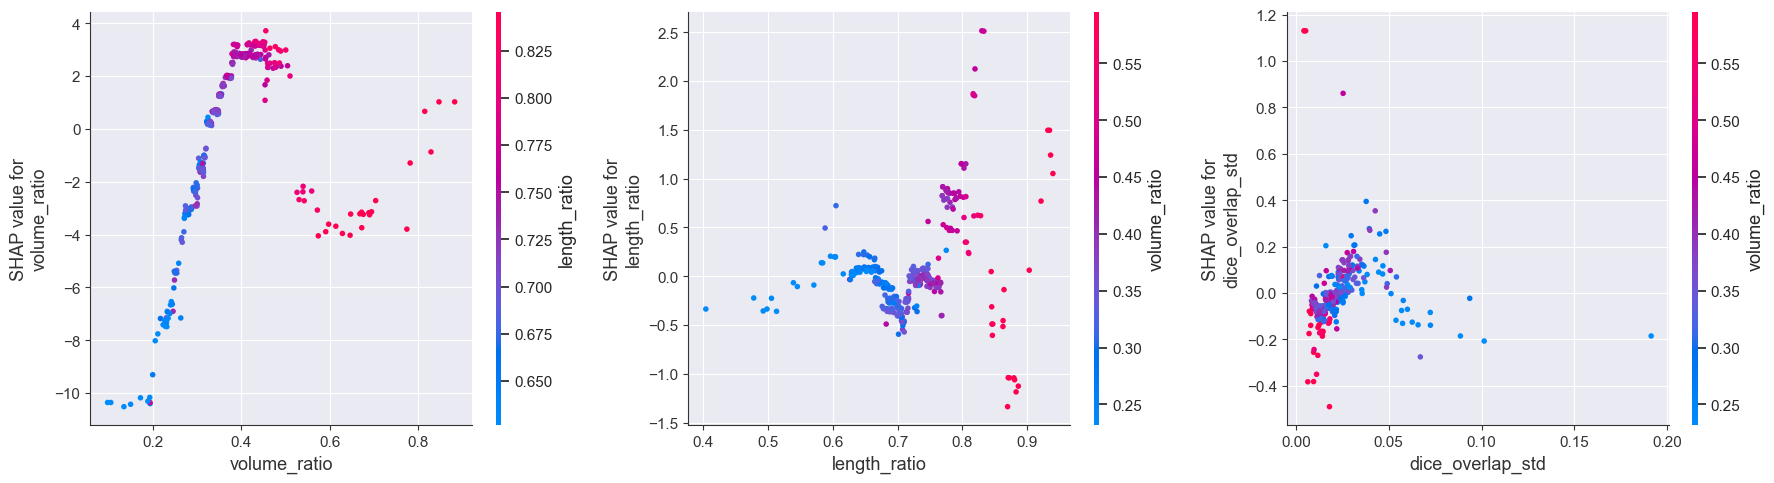

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="white", font_scale=1.0)

# volume_ratio colored by length_ratio (strongest interaction pair)
shap.dependence_plot(
    'volume_ratio', shap_values, X_test,
    interaction_index='length_ratio', ax=axes[0], show=False
)

# length_ratio colored by volume_ratio
shap.dependence_plot(
    'length_ratio', shap_values, X_test,
    interaction_index='volume_ratio', ax=axes[1], show=False
)

# dice_overlap_std colored by volume_ratio (its strongest interaction)
shap.dependence_plot(
    'dice_overlap_std', shap_values, X_test,
    interaction_index='volume_ratio', ax=axes[2], show=False
)

plt.tight_layout()
plt.savefig('../figures/shap_dependence.png', dpi=200, bbox_inches='tight')
plt.show()

- **volume_ratio**: its effect is not a straight line. Very low values
  push the correction strongly downward, the effect then rises sharply and
  levels off around 0.4-0.5, and drops again for higher values. This means
  the model treats both very low and very high volume ratios as unusual,
  not just "the higher the better."

- **length_ratio**: shows a weaker, more scattered upward trend — higher
  values tend to push the correction slightly up, but less clearly than
  volume_ratio. Points with high volume_ratio (pink) tend to have more
  negative SHAP values at the high end, matching the moderate interaction
  seen earlier between these two features.

- **dice_overlap_std**: has by far the smallest effect on the correction,
  with no clear pattern — confirming it is the least important of the
  three features.